# CM2 : fonctions de plusieurs dimensions

### Limites

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm

%matplotlib inline

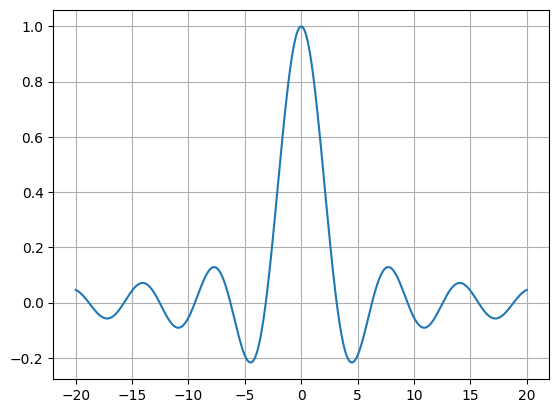

In [2]:
x = np.linspace(-20, 20, 500)
y = np.sin(x)/x
plt.plot(x,y)
plt.grid(True)
plt.show()
# print(x[245:255])

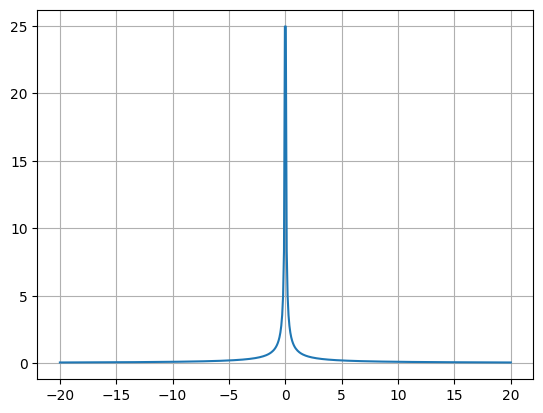

In [3]:
z = 1/(np.abs(x))
plt.plot(x,z)
plt.grid(True)
plt.show()

## Surfaces

In [4]:
def surface(x,y,z,titre):
    fig = plt.figure()
    axes = fig.add_subplot(projection='3d')
    axes.plot_surface(x, y, z)
    axes.set_title(titre)
    plt.show()

def cross_sec(x,z,titre='vide', leg=None):

    fig = plt.figure()
    #axes = fig.add_subplot(projection='3d')
    plt.plot(x, z)
    plt.legend(leg)
    plt.title(titre)
    plt.show()

## Tracer les sections à x ou y constant

Soit la fonction $f(x,y) = x^2 + \sin(y)$ et la fonction $g(x,y) =x^2+y^2$

(100,)
(100, 100)


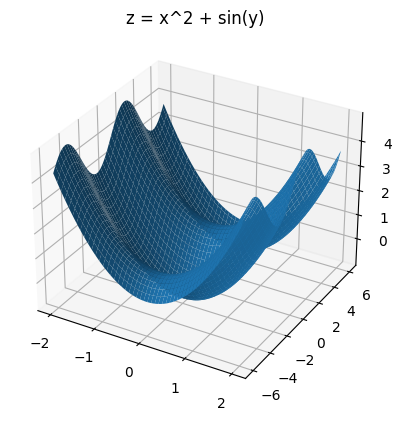

In [5]:
def fxy(x,y):
    return x**2 + np.sin(y)

titre = 'z = x^2 + sin(y)'

x = np.linspace(-2, 2, 100)
y = np.linspace(-6, 6, 100)
print(y.shape)
x, y = np.meshgrid(x,y)
print(y.shape)
f = fxy(x,y)
surface(x,y,f,titre)

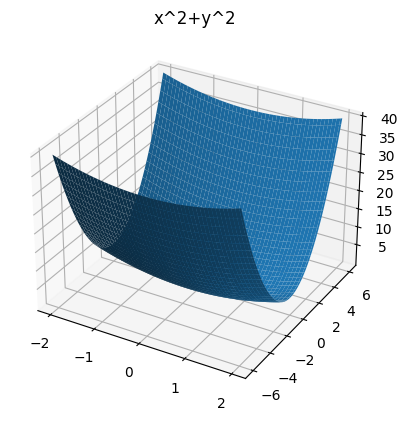

In [6]:
def gxy(x,y):
    return x**2 + y**2
titre='x^2+y^2'

g = gxy(x,y)
surface(x,y,g,titre)

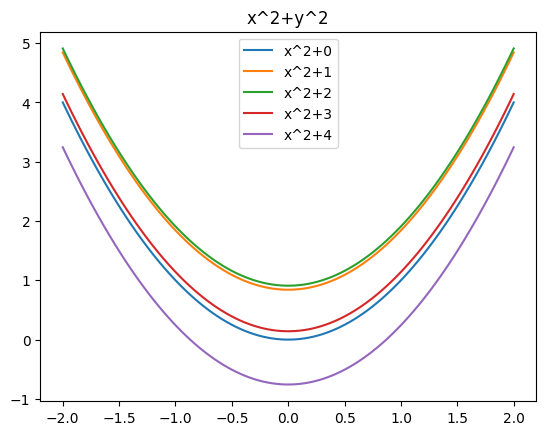

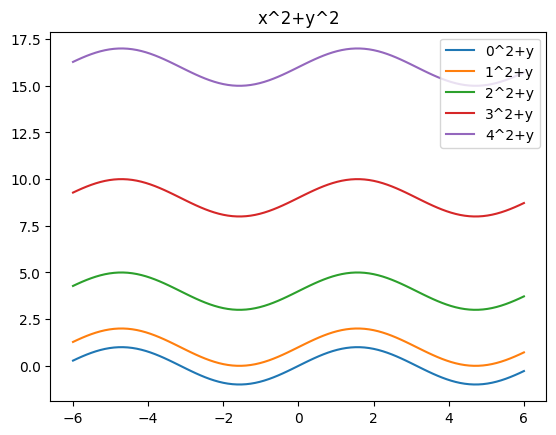

In [7]:
x = np.linspace(-2, 2, 100)
y = np.linspace(-6, 6, 100)

fx = np.transpose([fxy(x,a) for a in range(0,5)])
leg = ['x^2+%s'%(a) for a in range(0,5)]
cross_sec(x,fx,titre, leg)

fy = np.transpose([fxy(b,y) for b in range(0,5)])
leg = ['%s^2+y'%(b) for b in range(0,5)]
cross_sec(y,fy, titre, leg)

## Tracer des isoclines

Tracer les isoclines pour la fonction $g(x,y) = x^2 + y^2$. Il s'agit de tracer les points $(x,y)$ tels que $g(x,y)=c^{te}$

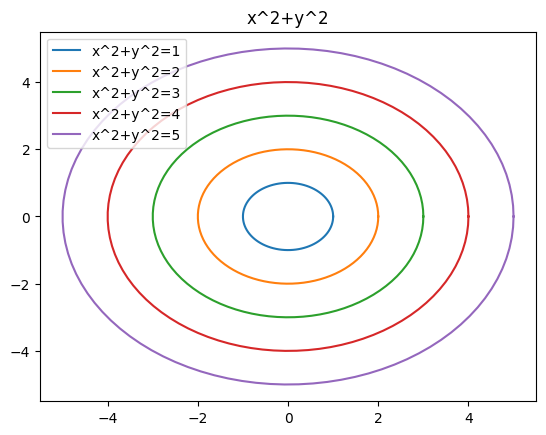

In [8]:
def isocline1(theta, titre='vide'):
    fig = plt.figure()
    axes = fig.gca()

    for r in range(1,6):
        x1 = r* np.cos(theta)
        x2 = r* np.sin(theta)
        axes.plot(x1,x2)

    leg = ['x^2+y^2=%s'%(r) for r in range(1,6)]
    axes.legend(leg)
    axes.set_title(titre)
    plt.show()
    
    
theta = np.linspace(0, 2*np.pi, 100)
isocline1(theta,titre)

Pour tracer les isoclines on peut utiliser la fonctions `contour` directement.

In [9]:
def isocline2(x,y,z, titre='vide'):
    fig = plt.figure()
    axes = fig.gca()
    axes.contour(x,y, z, 20)
    axes.set_title(titre)
    #axes.legend(leg)
    plt.show()

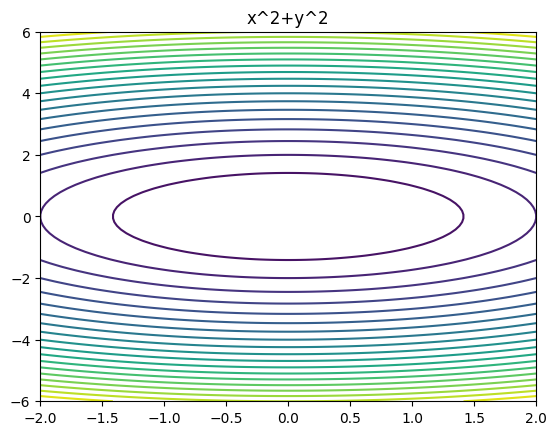

In [10]:
x, y = np.meshgrid(x,y)
z = gxy(x,y)
isocline2(x,y,z,titre)

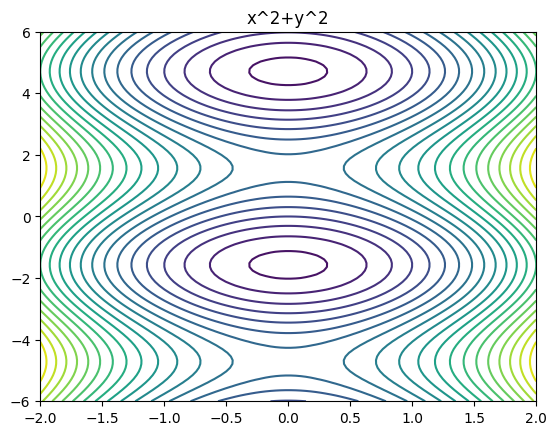

In [11]:
z = fxy(x,y) #x**2 + np.sin(y)

isocline2(x,y,z, titre)

### images en niveau de gris

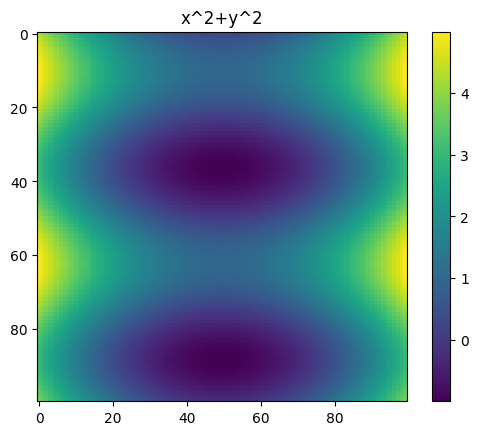

In [12]:
plt.imshow(z)
plt.title(titre)
plt.colorbar()
plt.show()

## Plan tangent

/var/folders/j7/jywdlhcd7r5_2kw1s36q8glr00022l/T/ipykernel_62511/3882214277.py:3: MatplotlibDeprecationWarning: Calling gca() with keyword arguments was deprecated in Matplotlib 3.4. Starting two minor releases later, gca() will take no keyword arguments. The gca() function should only be used to get the current axes, or if no axes exist, create new axes with default keyword arguments. To create a new axes with non-default arguments, use plt.axes() or plt.subplot().
  axes = fig.gca(projection='3d')


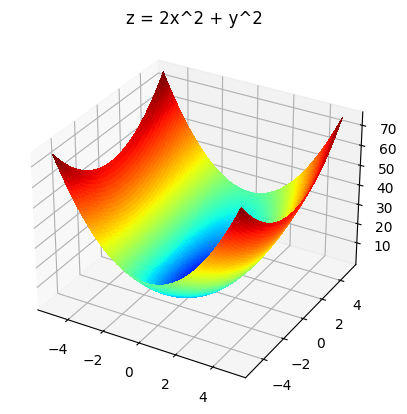

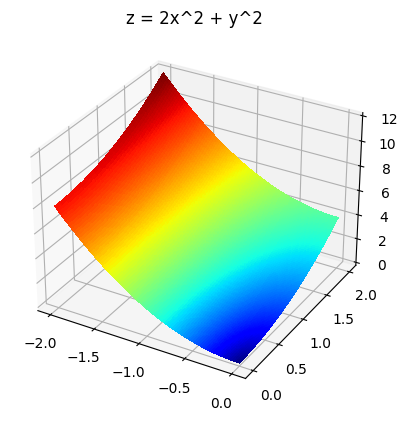

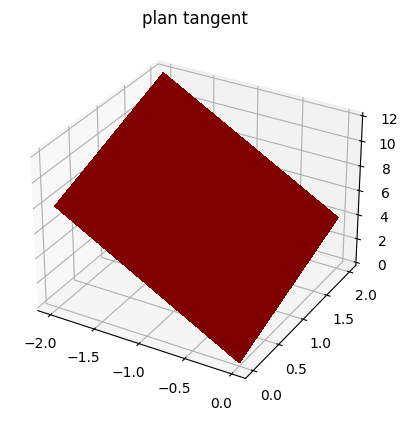

In [13]:
def surface(x,y,z,titre):
    fig = plt.figure()
    axes = fig.gca(projection='3d')
    Gx, Gy = np.gradient(z) # gradients with respect to x and y
    G = (Gx**2+Gy**2)**.5  # gradient magnitude
    N = G/G.max()  # normalize 0..1
    axes.plot_surface(
        x, y, z, rstride=1, cstride=1,
        facecolors=cm.jet(N),
        linewidth=0, antialiased=False, shade=False)
    axes.set_title(titre)
    plt.show()
    
def fxy(x,y):
    return 2*x*x + y*y
    #return np.log(1+x*x+y*y)

def plan(x,y):
    return -4*x + 2*y

titre = 'z = 2x^2 + y^2'

x = np.linspace(-5, 5, 100)
y = np.linspace(-5, 5, 100)
x, y = np.meshgrid(x,y)
f = fxy(x,y)

xr = np.linspace(-2, 0, 100)
yr = np.linspace(0, 2, 100)
xr, yr = np.meshgrid(xr,yr)
fr = fxy(xr,yr)
surface(x,y,f,titre)
surface(xr,yr,fr,titre)
surface(xr,yr,plan(xr,yr), 'plan tangent')

In [3]:
def td3(x,y):
    return x**2/y + y
def plan_tgt(x,y):
    return x + 3/4*y

print( td3(.5,1), plan_tgt(.5,1))
print( td3(.55,.9), plan_tgt(.55,.9))

1.25 1.25
1.2361111111111112 1.225
